# 04 · Autoencoder (Fase 4)
Detección de anomalías: un autoencoder convolucional se entrena **solo con piezas buenas** (nunca ve un defecto). Aprende a reconstruir la textura normal; un defecto se reconstruye mal y el **error de reconstrucción** lo delata. No usa etiquetas de defecto para entrenar.

**Protocolo (igual que baseline y CNN):** la validación (con etiquetas) solo elige época, variante de score y umbral (máx. F2 en val). El test no se toca: se usa una vez en la Fase 5.

**Score de imagen:** a partir del mapa de error por píxel. Un defecto es chico (mediana 1,6 % de la imagen), así que el promedio lo diluye; se prueban `mean`, `top5` (promedio del 5 % de píxeles peor reconstruidos), `top1` y `max`, y se elige la mejor por AP en validación.

Hipótesis: el autoencoder queda por debajo de la CNN supervisada (no usa ninguna etiqueta de defecto), pero detecta defectos que la CNN no vio y no depende de tener muchas defectuosas.

**Primero `SMOKE = True`** (≈ 1 min); luego `False`.

In [1]:
# --- Bootstrap: same cell at the top of every notebook ---
import os
import subprocess
import sys
from pathlib import Path

REPO = "matifleman/inspectia"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive, userdata

    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/InspectIA")
    REPO_DIR = Path("/content/inspectia")
    if REPO_DIR.exists():
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", f"https://github.com/{REPO}.git", str(REPO_DIR)], check=True)
    os.environ["WANDB_API_KEY"] = userdata.get("WANDB_API_KEY")
else:
    REPO_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DRIVE_ROOT = REPO_DIR
    if "WANDB_API_KEY" not in os.environ:
        os.environ["WANDB_MODE"] = "offline"  # local runs without a key log offline

os.chdir(REPO_DIR)
if IN_COLAB:  # locally, install once in your venv (see README)
    %pip install -q -r requirements.txt -e .
# Editable installs are only picked up after a kernel restart; this makes the
# package importable in the current session too.
sys.path.insert(0, str(REPO_DIR / "src"))

DATA_DIR = DRIVE_ROOT / "data"
CHECKPOINT_DIR = DRIVE_ROOT / "checkpoints"
SPLITS_DIR = DRIVE_ROOT / "splits"

from inspectia.utils import get_device, set_seed

SEED = 42
set_seed(SEED)
device = get_device()
print(f"Repo: {REPO_DIR} | Data: {DATA_DIR} | Device: {device}")

Repo: /Users/ipejinakis/Documents/Ingenieria-UCA/Inteligencia Artificial/InspectIA/repo | Data: /Users/ipejinakis/Documents/Ingenieria-UCA/Inteligencia Artificial/InspectIA/repo/data | Device: mps


In [2]:
# Paths shared by every notebook after the bootstrap
DATASET_DIR = DATA_DIR / "KolektorSDD2"
SPLITS_DIR = REPO_DIR / "splits"            # versioned in git: the whole team uses the SAME splits
RESULTS_DIR = DRIVE_ROOT / "results"
FEATURES_DIR = DRIVE_ROOT / "features"
for d in (SPLITS_DIR, RESULTS_DIR, FEATURES_DIR, CHECKPOINT_DIR):
    d.mkdir(parents=True, exist_ok=True)

In [9]:
import json, copy
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
from inspectia.data import get_splits, make_ae_loaders, InspectDataset, get_transforms
from inspectia.models import build_autoencoder
from inspectia.train import fit_autoencoder, anomaly_scores, save_checkpoint, SCORE_VARIANTS
from inspectia.evaluate import (evaluate, best_f2_threshold, bootstrap_ci, trivial_baselines, plot_confusion)
from inspectia.utils import load_config, init_wandb, get_device, set_seed
from sklearn.metrics import average_precision_score, roc_auc_score

CONFIG = "autoencoder_b2.yaml"
SMOKE = False              # True = prueba rápida (1 época, 3 lotes); False = entrenamiento real
SEED_OVERRIDE = 2      # None = seed del YAML (42); 1, 2 = corridas extra (guardan *_s1, *_s2)

cfg = load_config(REPO_DIR / "configs" / CONFIG)
if SEED_OVERRIDE is not None:
    cfg["seed"] = SEED_OVERRIDE; cfg["name"] = f"{cfg['name']}_s{SEED_OVERRIDE}"
set_seed(cfg["seed"]); device = get_device()
MAX_BATCHES = 3 if SMOKE else None
print("config:", CONFIG, "| device:", device, "| SMOKE:", SMOKE)

splits = get_splits(DATASET_DIR, SPLITS_DIR, cfg["data"]["val_frac"], 42)   # mismo split siempre
loaders = make_ae_loaders(DATASET_DIR, splits, cfg["data"]["batch_size"], tuple(cfg["data"]["img_size"]),
                          cfg["data"]["num_workers"], augment=cfg["data"]["augment"], seed=cfg["seed"])
print("train (solo buenas):", len(loaders["train_good"].dataset), "| val:", len(loaders["val"].dataset),
      "con", int(splits["val"]["label"].sum()), "defectuosas")
run = None if SMOKE else init_wandb(cfg, name=cfg["name"], group=cfg["wandb"]["group"], project=cfg["wandb"]["project"])

config: autoencoder_b2.yaml | device: mps | SMOKE: False
train (solo buenas): 1667 | val: 467 con 49 defectuosas


## 1. Entrenamiento (solo piezas buenas, pérdida MSE de reconstrucción)

In [10]:
m = cfg["model"]; t = cfg["train"]
model = build_autoencoder(m["base"], m["bottleneck"]).to(device)
print("parámetros:", sum(p.numel() for p in model.parameters()))
history = fit_autoencoder(model, loaders, device, 1 if SMOKE else t["epochs"], t["lr"], t["weight_decay"],
                          t["patience"], t["monitor"], t["smooth"], MAX_BATCHES, run)

parámetros: 198453
[ae] ep 1/30 | train_mse 0.1577 | val_mse 0.0211 | val_AP(top1) 0.7915 | val_AUC 0.8980 | val_F2 0.7308 | 22s
[ae] ep 2/30 | train_mse 0.0236 | val_mse 0.0196 | val_AP(top1) 0.7661 | val_AUC 0.8858 | val_F2 0.6992 | 16s
[ae] ep 3/30 | train_mse 0.0210 | val_mse 0.0186 | val_AP(top1) 0.7548 | val_AUC 0.8784 | val_F2 0.6890 | 16s
[ae] ep 4/30 | train_mse 0.0205 | val_mse 0.0178 | val_AP(top1) 0.7533 | val_AUC 0.8775 | val_F2 0.6890 | 16s
[ae] ep 5/30 | train_mse 0.0191 | val_mse 0.0185 | val_AP(top1) 0.7536 | val_AUC 0.8758 | val_F2 0.6917 | 16s
[ae] ep 6/30 | train_mse 0.0193 | val_mse 0.0181 | val_AP(top1) 0.7527 | val_AUC 0.8758 | val_F2 0.7028 | 16s
[ae] ep 7/30 | train_mse 0.0187 | val_mse 0.0177 | val_AP(top1) 0.7581 | val_AUC 0.8747 | val_F2 0.7115 | 18s
[ae] early stopping (no improvement in 6 epochs)
[ae] best val_AP(top1) = 0.7915


## 2. Curvas de aprendizaje
Pérdida de reconstrucción en train (solo buenas) y en val (todas), y AP de validación del score elegido para early stopping.

,epoch,train_loss,val_mse,val_ap,val_auc,val_f2,seconds
0,1,0.1577,0.0211,0.7915,0.8980,0.7308,21.5579
1,2,0.0236,0.0196,0.7661,0.8858,0.6992,15.7122
2,3,0.0210,0.0186,0.7548,0.8784,0.6890,15.8590
3,4,0.0205,0.0178,0.7533,0.8775,0.6890,15.9625
4,5,0.0191,0.0185,0.7536,0.8758,0.6917,16.0852
5,6,0.0193,0.0181,0.7527,0.8758,0.7028,16.3950
6,7,0.0187,0.0177,0.7581,0.8747,0.7115,17.7525


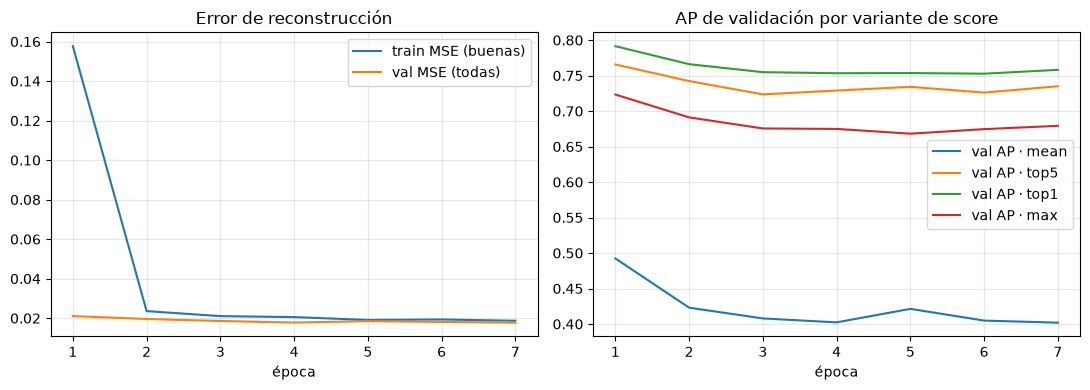

In [11]:
h = pd.DataFrame(history); h["it"] = range(1, len(h) + 1)
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
a.plot(h["it"], h["train_loss"], label="train MSE (buenas)"); a.plot(h["it"], h["val_mse"], label="val MSE (todas)")
a.set(title="Error de reconstrucción", xlabel="época"); a.legend(); a.grid(alpha=.3)
for k in SCORE_VARIANTS:
    b.plot(h["it"], h[f"ap_{k}"], label=f"val AP · {k}")
b.set(title="AP de validación por variante de score", xlabel="época"); b.legend(); b.grid(alpha=.3)
plt.tight_layout(); h[["epoch", "train_loss", "val_mse", "val_ap", "val_auc", "val_f2", "seconds"]].round(4)

## 3. ¿Qué reconstruye? (control visual)
Fila 1: original · fila 2: reconstrucción · fila 3: mapa de error. En las defectuosas el error tiene que concentrarse sobre el defecto (contorno rojo en la fila 1).

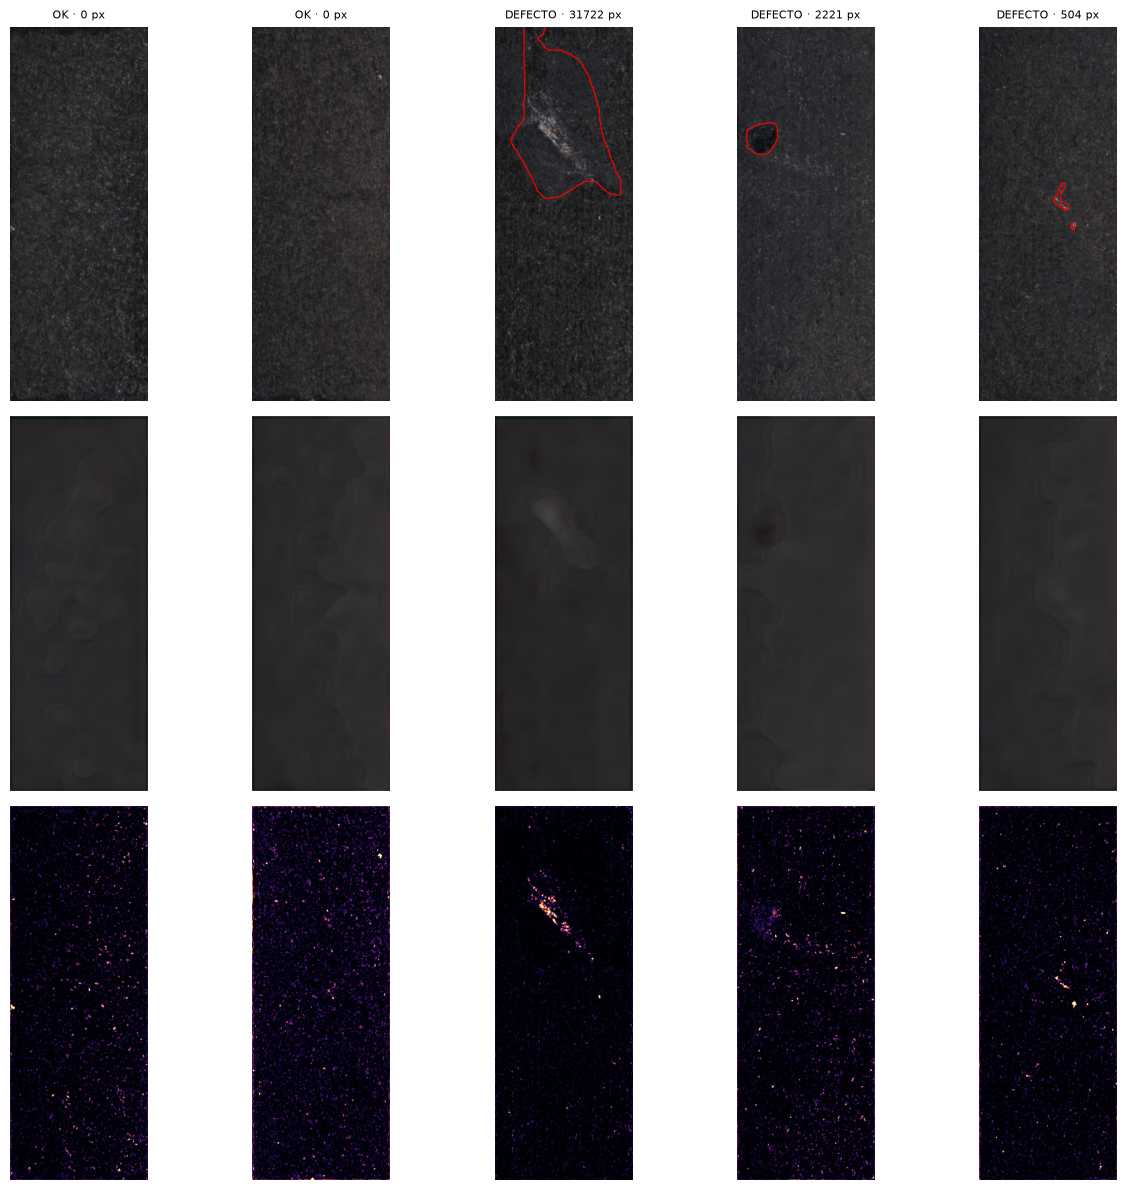

In [12]:
from inspectia.data import load_mask
mean, std = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1), torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
val_df = splits["val"]
pick = list(val_df[val_df["label"] == 0].index[:2]) + list(val_df[val_df["label"] == 1].sort_values("defect_px").index[[-1, len(val_df[val_df["label"] == 1]) // 2, 3]])
ds = InspectDataset(val_df, DATASET_DIR, get_transforms(False, tuple(cfg["data"]["img_size"])))
model.eval()
fig, ax = plt.subplots(3, len(pick), figsize=(2.6 * len(pick), 12))
with torch.no_grad():
    for j, idx in enumerate(pick):
        x, y = ds[val_df.index.get_loc(idx)]
        xh = model(x.unsqueeze(0).to(device)).cpu()[0]
        err = ((xh - x) ** 2).mean(0)
        ax[0, j].imshow((x * std + mean).permute(1, 2, 0).clamp(0, 1)); ax[0, j].set_title(("DEFECTO" if y else "OK") + f" · {val_df.loc[idx, 'defect_px']} px", fontsize=8)
        ax[1, j].imshow((xh * std + mean).permute(1, 2, 0).clamp(0, 1))
        ax[2, j].imshow(err, cmap="inferno", vmax=float(np.percentile(err.numpy(), 99.9)))
        if y:
            mk = load_mask(DATASET_DIR, val_df.loc[idx, "mask"])
            from PIL import Image
            mk = np.array(Image.fromarray(mk).resize(tuple(cfg["data"]["img_size"])[::-1], Image.NEAREST)) > 0
            ax[0, j].contour(mk, levels=[0.5], colors="r", linewidths=0.8)
for a_ in ax.ravel(): a_.axis("off")
plt.tight_layout()

## 4. Evaluación en validación
Se elige la variante de score con mejor **AP en validación** (es un hiperparámetro, se decide con val). El umbral = máx. F2 en validación, igual que los demás modelos. Los scores del autoencoder no son probabilidades: el umbral solo sirve para este score.

,AP,AUC
mean,0.492,0.724
top5,0.766,0.883
top1,0.791,0.898
max,0.723,0.869


variante elegida (mejor AP en val): top1


,model,threshold,f2,recall,precision,auc_roc,avg_precision,fn,fp
0,baseline resnet18 + logística,0.671,0.816,0.816,0.816,0.962,0.880,9,9
1,cnn_resnet18,0.663,0.918,0.918,0.918,0.981,0.955,4,4
2,autoencoder_b2_s2 (top1),0.125,0.731,0.776,0.594,0.898,0.791,11,26


IC 95% F2: (0.64, 0.82) | recall: (0.67, 0.88)
           accuracy  recall  precision    f2
always_ok     0.895     0.0      0.000  0.00
flag_all      0.105     1.0      0.105  0.37


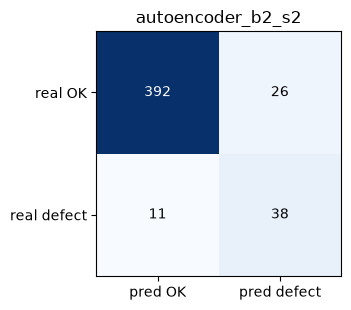

In [13]:
y_va, variants, val_mse = anomaly_scores(model, loaders["val"], device, cfg["train"]["smooth"], MAX_BATCHES)
tab = pd.DataFrame({k: {"AP": average_precision_score(y_va, v), "AUC": roc_auc_score(y_va, v)} for k, v in variants.items()}).T
display(tab.round(3))
best_variant = tab["AP"].idxmax(); s_va = variants[best_variant]
print("variante elegida (mejor AP en val):", best_variant)
thr = best_f2_threshold(y_va, s_va)
mt = evaluate(y_va, s_va, thr); ci = bootstrap_ci(y_va, s_va, thr)
rows = []
for name, f in (("baseline resnet18 + logística", "baseline_val.json"), ("cnn_resnet18", "cnn_resnet18_val.json")):
    p = RESULTS_DIR / f
    if p.exists():
        d = json.load(open(p))
        if isinstance(d, list): d = sorted([r for r in d if r["model"].startswith("resnet18")], key=lambda r: -r["avg_precision"])[0]
        else: d = {"threshold": d["threshold"], **d["val"]}
        rows.append({"model": name, **{k: d[k] for k in ("threshold", "f2", "recall", "precision", "auc_roc", "avg_precision", "fn", "fp")}})
rows.append({"model": f"{cfg['name']} ({best_variant})", **{k: mt[k] for k in ("threshold", "f2", "recall", "precision", "auc_roc", "avg_precision", "fn", "fp")}})
display(pd.DataFrame(rows).round(3))
print("IC 95% F2:", tuple(round(v, 2) for v in ci["f2"]), "| recall:", tuple(round(v, 2) for v in ci["recall"]))
print(pd.DataFrame(trivial_baselines(y_va)).T.round(3))
plot_confusion(mt, cfg["name"]);

## 5. Guardar (solo corrida real)

In [14]:
if not SMOKE:
    save_checkpoint(model, CHECKPOINT_DIR / f"{cfg['name']}.pt")
    json.dump({"config": cfg, "score_variant": best_variant, "variant_table": tab.round(4).to_dict(), "threshold": thr,
               "val": mt, "val_ci": ci}, open(RESULTS_DIR / f"{cfg['name']}_val.json", "w"), indent=2)
    np.savez(RESULTS_DIR / f"{cfg['name']}_val_scores.npz", y=y_va, scores=s_va, **{f"scores_{k}": v for k, v in variants.items()})
    h.to_json(RESULTS_DIR / f"{cfg['name']}_history.json", orient="records", indent=2)
    if run:
        run.summary.update({f"val/{k}": v for k, v in mt.items() if isinstance(v, float)}); run.finish()
    print("Guardado en", CHECKPOINT_DIR, "y", RESULTS_DIR)
else:
    print("SMOKE: no se guarda nada. Si corrió sin errores, SMOKE = False y repetir desde la celda de configuración.")

ae/ap_max,█▄▂▂▁▂▂
ae/ap_mean,█▃▁▁▃▁▁
ae/ap_top1,█▃▁▁▁▁▂
ae/ap_top5,█▄▁▂▃▁▃
ae/epoch,▁▂▃▅▆▇█
ae/seconds,█▁▁▁▁▂▃
ae/train_loss,█▁▁▁▁▁▁
ae/val_ap,█▃▁▁▁▁▂
ae/val_auc,█▄▂▂▁▁▁
ae/val_f2,█▃▁▁▁▃▅
+1,...


Guardado en /Users/ipejinakis/Documents/Ingenieria-UCA/Inteligencia Artificial/InspectIA/repo/checkpoints y /Users/ipejinakis/Documents/Ingenieria-UCA/Inteligencia Artificial/InspectIA/repo/results


## Registro del experimento
Completar con los números reales (no estimar). Un cambio por corrida (`bottleneck`, `base`, `monitor`, `augment`).

| Corrida | Cambio | Variante | F2 val | Recall val | AP val | AUC val |
|---|---|---|---|---|---|---|
| `autoencoder.yaml` | base (bottleneck 16) | | | | | |

Interpretación y próximo paso: *(redactar con los resultados)*.